# Watch IMPRESS adapt

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/radical-collaboration/IMPRESS/blob/main/docs/notebooks/impress_adaptive_quickstart.ipynb)

Location: [`examples/colab/`](https://github.com/radical-collaboration/IMPRESS/tree/main/examples/colab)

Every other example in this repository needs an allocation, a GPU and model
weights. This one needs a browser tab. It runs a real IMPRESS pipeline that
watches its own results get worse and spawns a child pipeline to deal with it,
and then shows you what that did to the run.

About **40 seconds** end to end, plus a minute for the install the first time.

## What is real here, and what is not

Real: `ImpressManager`, `WorkflowEngine` on asyncflow's `LocalExecutionBackend`,
executable tasks that start actual subprocesses, and genuine adaptive
child-pipeline spawning through `submit_child_pipeline_request`.

Not real: the science. **Every score below is a seeded pseudo-random draw and
says nothing about any protein.** What you are measuring is the framework's
behaviour -- when it reacts, and what reacting costs -- not a property of a
molecule.

## Setup

Installs `impress` and clones the repository for the helper module. Safe to
re-run: it does nothing if the framework is already importable.

`--no-deps` is deliberate. `impress` declares `radical.pilot`, but never imports
it -- the only `radical` import in its source is `radical.asyncflow` -- and
`radical.pilot` ships as an sdist with a C extension. Skipping it turns a
multi-minute cell into a few seconds. Install it normally when you are going to
a real HPC backend.

In [1]:
import importlib.util
import pathlib
import subprocess
import sys

CLONE = pathlib.Path("IMPRESS")
CHECKOUT = pathlib.Path("../..")  # when this notebook is run from inside the repository

# The helper module lives in the repository, not in the installed package, so the
# clone is needed whether or not the framework is already importable. Kept out of
# the install guard for that reason: the two are not the same condition.
if not (CHECKOUT / "examples/colab").is_dir() and not CLONE.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/radical-collaboration/IMPRESS.git", str(CLONE)],
        check=True,
    )

if importlib.util.find_spec("impress") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q",
         "radical.asyncflow>=0.5.1", "pydantic", "matplotlib"],
        check=True,
    )
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "--no-deps", str(CLONE)],
        check=True,
    )
    print("installed")
else:
    print("impress is already importable - nothing to install")

for candidate in (CHECKOUT / "examples/colab", CLONE / "examples/colab"):
    if (candidate / "impress_toy.py").exists():
        sys.path.insert(0, str(candidate.resolve()))
        break
else:
    raise RuntimeError("could not find examples/colab")

impress is already importable - nothing to install


In [2]:
%matplotlib inline
import impress
import toy_figures as tf
from impress_toy import run_sweep, run_toy, summary_table
from toy_science import ToyConfig, decide, fragile_targets

tf.apply_style()
print("python  ", sys.version.split()[0])
print("impress ", impress.__file__)

python   3.10.12
impress  /tmp/claude-1000/-home-mason-exdrive-rad-IMPRESS/d99d1ac7-5f32-412e-9864-57f219dc479a/scratchpad/nbenv/lib/python3.10/site-packages/impress/__init__.py


## The rule the pipeline adapts on

A pipeline runs several **passes** over a set of **targets**. After each pass it
calls `await self.run_adaptive_step(wait=True)`, and the manager runs the
adaptive function below against the live pipeline.

The rule compares this pass's score for each target against the last one. A
target whose score fell by more than `degradation_threshold` is *degraded*. If
enough targets are degraded, the pipeline hands them to a **child pipeline** and
stops working on them itself -- the same shape as the real protein-binding
example, which migrates degraded targets into a sub-pipeline.

Two details that are easy to get wrong, and that this notebook depends on:

* The adaptive function must be a **declared engine task**, not a plain
  function. `PipelineSetup` raises `TypeError` otherwise, and so does a child
  configuration that carries a bare coroutine.
* The **generation cap is yours to enforce.** The framework has no generation
  concept and no limit of its own. `ImpressManager.start()` returns when no
  pipeline is left, so a rule that always spawns never returns.

In [3]:
import inspect

print(inspect.getsource(decide))

def decide(
    current: dict,
    previous: dict,
    generation: int,
    cfg: ToyConfig,
) -> SpawnDecision:
    """The adaptive rule itself, as a pure function.

    Kept separate from the callback that runs on the engine so it can be tested
    without a `WorkflowEngine`, and so the notebook can show the rule without
    showing the plumbing around it.
    """
    degraded = tuple(
        v.target for v in verdicts(current, previous, cfg.degradation_threshold)
        if v.degraded
    )
    if generation >= cfg.max_generations:
        return SpawnDecision(
            False,
            f"no spawn: generation cap reached ({generation}/{cfg.max_generations})",
            degraded,
        )
    if len(degraded) < cfg.min_degraded_to_spawn:
        return SpawnDecision(
            False,
            f"no spawn: {len(degraded)} degraded, "
            f"{cfg.min_degraded_to_spawn} needed",
            degraded,
        )
    return SpawnDecision(
        True,
        f"spawn: {

## Set the knobs

`degradation_threshold` is the one to play with: it decides how big a drop
counts as a target going wrong, so it directly controls how much the run
adapts. Lower it and the pipeline spawns more children.

In [4]:
import os

degradation_threshold = 2.0  # @param {type:"number"}
max_generations = 2  # @param {type:"integer"}
n_targets = 6  # @param {type:"integer"}
n_passes = 3  # @param {type:"integer"}
seed = 7  # @param {type:"integer"}

if os.environ.get("IMPRESS_NB_SMALL"):
    # Continuous integration executes this notebook on a small configuration.
    n_targets, n_passes = 4, 2

cfg = ToyConfig(
    n_targets=n_targets,
    n_passes=n_passes,
    degradation_threshold=degradation_threshold,
    max_generations=max_generations,
    seed=seed,
)
print(f"targets          {' '.join(sorted(fragile_targets(cfg)))} will tend to decline")
print(f"threshold        a drop of more than {cfg.degradation_threshold} marks a target degraded")
print(f"spawn when       {cfg.min_degraded_to_spawn} or more targets are degraded")
print(f"generation cap   {cfg.max_generations}")

targets          T1 T3 T6 will tend to decline
threshold        a drop of more than 2.0 marks a target degraded
spawn when       2 or more targets are degraded
generation cap   2


## Run it

Note the `await` with no `asyncio.run` around it. `WorkflowEngine` needs a
running event loop and a notebook already has one, so `asyncio.run` fails here.

Watch for three things in the log:

1. The six `structure_prediction` tasks of a pass all start at the same
   timestamp. Each is a real subprocess, and the pipeline collects their futures
   before awaiting any of them.
2. The first `adaptive_eval` declines to spawn -- the first pass has nothing to
   compare against.
3. When a spawn does happen, the parent's next pass runs over fewer targets. It
   handed them over.

In [5]:
result = await run_toy(cfg)

==================== IMPRESS MANAGER STARTING ====================


12:27:31.165 [INFO] [MANAGER] Starting with 1 initial pipelines


12:27:31.165 [INFO] [MANAGER] Pipeline started: p1


[  0.00s]  -                run_start     
[  0.01s]  p1          g0   pipeline_start  T1 T2 T3 T4 T5 T6
[  0.01s]  p1          g0   task_start      structure_prediction  pass 0  T1
[  0.01s]  p1          g0   task_start      structure_prediction  pass 0  T2
[  0.01s]  p1          g0   task_start      structure_prediction  pass 0  T3
[  0.01s]  p1          g0   task_start      structure_prediction  pass 0  T4
[  0.01s]  p1          g0   task_start      structure_prediction  pass 0  T5
[  0.01s]  p1          g0   task_start      structure_prediction  pass 0  T6


[  0.26s]  p1          g0   task_end        structure_prediction  pass 0  score 79.2  T1
[  0.26s]  p1          g0   task_end        structure_prediction  pass 0  score 87.1  T2
[  0.26s]  p1          g0   task_end        structure_prediction  pass 0  score 66.6  T3
[  0.26s]  p1          g0   task_end        structure_prediction  pass 0  score 73.6  T4
[  0.26s]  p1          g0   task_end        structure_prediction  pass 0  score 82.7  T5
[  0.26s]  p1          g0   task_end        structure_prediction  pass 0  score 71.7  T6
[  0.26s]  p1          g0   task_start      score_extraction      pass 0
[  0.26s]  p1          g0   task_end        score_extraction      pass 0  mean 76.8


12:27:31.666 [INFO] [ADAPTIVE] Adaptive function started for: p1


... (25 outputs left out)

12:27:36.180 [INFO] [MANAGER] Pipeline completed: p1.g1


12:27:36.181 [INFO] [MANAGER] All pipelines finished. Exiting.


==================== IMPRESS MANAGER FINISHED ====================


[  5.03s]  -                run_end       


In [6]:
tf.print_table(summary_table(result))

metric                value
--------------------  -----
pipelines             2    
generations reached   1    
children spawned      1    
tasks completed       28   
adaptive evaluations  6    
makespan (s)          5.03 


## Where the time went

Each bar runs from a task's submission to its future resolving. The gaps between
passes are **not** task work: they are the manager's adaptive poll. It notices
the flag on one 0.5s cycle and releases the pipeline on a later one, so every
`run_adaptive_step(wait=True)` costs about a second. On a real run, where a task
is a structure prediction, this is invisible. Here it is most of the clock, and
it is worth seeing once.

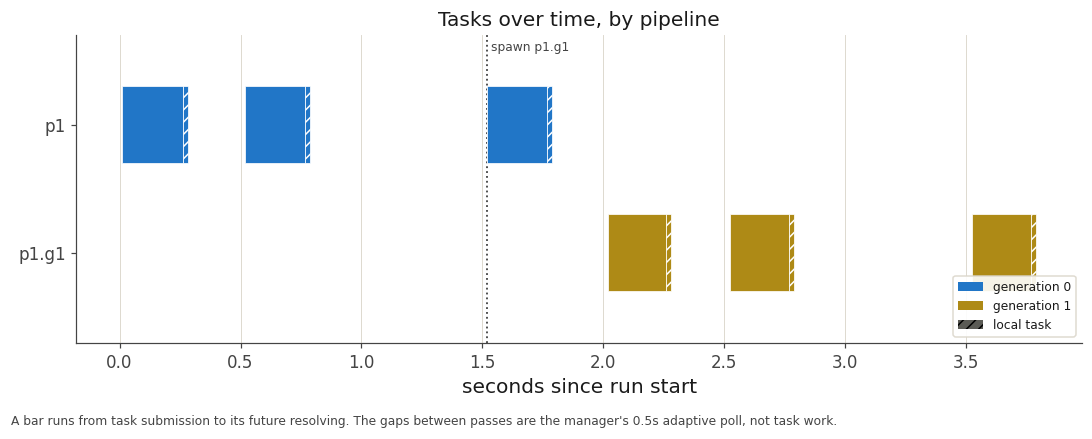

In [7]:
tf.plot_gantt(result);

## What the pipeline decided

One arrow per `submit_child_pipeline_request`. The label names the targets the
parent migrated and stopped working on.

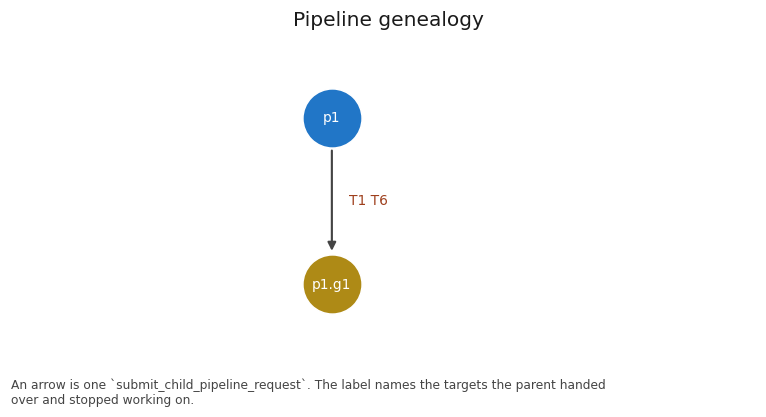

In [8]:
tf.plot_genealogy(result);

## Why it decided that

The dark red lines are the targets the simulation makes fragile. Where one
crosses into a child pipeline it turns blue and its slope flattens -- in this
model a child buys time, it does not repair the target. The dotted line marks
the spawn.

This is the figure to come back to after changing `degradation_threshold`: the
trajectories do not move, only the point at which the framework decides they
have gone far enough.

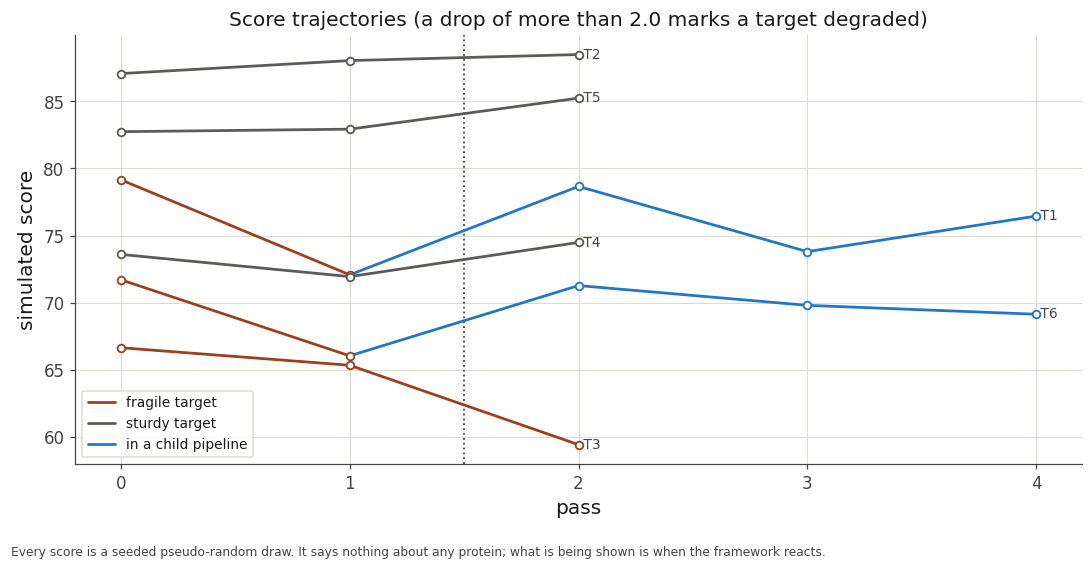

In [9]:
tf.plot_scores(result);

## How much ran at once

The peaks are one pass's targets running together.

The `max_workers` line is drawn for reference, and the run goes straight through
it. That is correct, not a bug: executable tasks are subprocesses started on the
event loop, so the thread pool does not bound them. It bounds *function* tasks
and the adaptive callback.

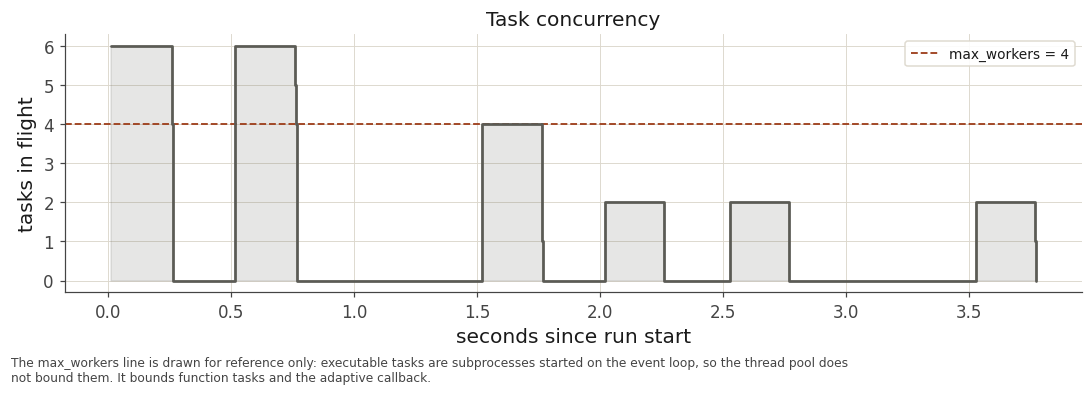

In [10]:
tf.plot_concurrency(result);

## Turning the knob

The same run at five thresholds. Each one is a complete, independent run with
its own engine -- which is also a check that the framework can be driven
repeatedly in a single kernel.

Expect spawning to fall to zero as the threshold rises past the biggest drop any
target takes, and the makespan to fall with it: adapting costs time.

In [11]:
thresholds = (0.5, 1.0, 2.0, 4.0, 8.0)
if os.environ.get("IMPRESS_NB_SMALL"):
    thresholds = (1.0, 8.0)

sweep = await run_sweep(cfg, "degradation_threshold", thresholds)
tf.print_table(sweep)

degradation_threshold  repeat  seed  pipelines  spawns  max_generation  makespan_s  mean_final_score
---------------------  ------  ----  ---------  ------  --------------  ----------  ----------------
0.5                    0       7     3          2       2               7.04        74.57           
1.0                    0       7     3          2       2               7.03        74.57           
2.0                    0       7     2          1       1               5.02        75.54           
4.0                    0       7     2          1       1               5.01        75.54           
8.0                    0       7     1          0       0               3.02        72.38           


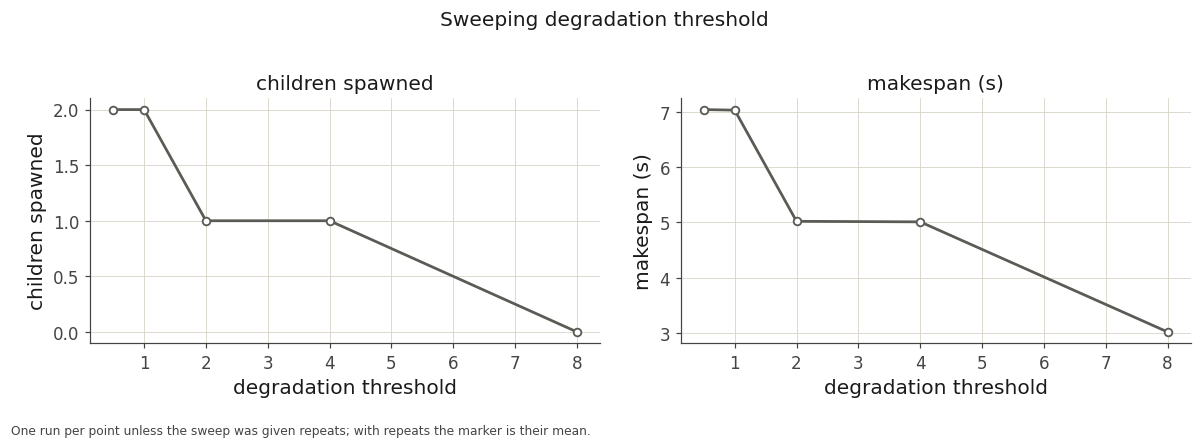

In [12]:
tf.plot_sweep(sweep, "degradation_threshold");

## Three things to try

**Set `max_generations` to 0.** Spawning stops entirely and every
`adaptive_eval` says why. This is the knob that keeps a recursive rule
terminating; without a cap of your own, `start()` never returns.

**Set `degradation_threshold` to 0.5.** Almost any wobble counts as degradation,
so the run spawns until it hits the generation cap. Compare the genealogy to the
one above.

**Set `n_targets` to 12.** The concurrency figure's peaks double while
`max_workers` stays where it is -- the demonstration that the thread pool is not
what bounds these tasks.

## Where to go next

* [Adaptive Execution](../concepts/adaptive-execution.md) -- the same mechanism, explained rather than run.
* [Architecture](../concepts/architecture.md) -- what the manager, the pipeline and the engine each own.
* [Protein Binding](../examples/protein-binding.md) -- the real version of the rule used here: ProteinMPNN and Boltz-2 on Delta, migrating degraded targets into sub-pipelines.
* [Small Molecule Binding](../examples/small-molecule-binding.md) and [Discontinuous Scaffolds](../examples/discontinuous-scaffolds.md) -- two more production campaigns.
* [IMPRESS-A](../impress-a/index.md) -- what happens when the decision above is made by an agent instead of a rule.